# **study data 실습**

In [ ]:
## 기타 다양한 변수 조합으로 시각화 -> insight 도출

In [ ]:
## study data 탐색

In [11]:
## 필요한 라이브러리 불러오기
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 데이터 로드
df_study = pd.read_csv('/content/Study.공유.csv')

print(f"[행·렬 수]")
print(df_study.shape)   # 행: 약 3만 개, 열: 19개 → 분석하기에 충분히 많은가?

print(f"\n[열 목록 확인]")
print(df_study.columns)   #  열 목록 확인 → 무엇을 알아내고 싶은가?

print(f"\n[간단한 EDA]")
df_study.head()   # 5개 행 확인

[행·렬 수]
(30664, 19)

[열 목록 확인]
Index(['ID', 'survived', 'Month', 'AGE', 'StudyCnt_M1', 'StudyCntCnt_M2',
       'StudyCntCnt_M3', 'StudyIndex_M1', 'StudyIndex_M2', 'StudyIndex_M3',
       'Exam1_M1', 'Exam1_M2', 'Exam1_M3', 'Exam2_M1', 'Exam2_M2', 'Exam2_M3',
       'Exam3_M1', 'Exam3_M2', 'Exam3_M3'],
      dtype='object')

[간단한 EDA]


,ID,survived,Month,AGE,StudyCnt_M1,StudyCntCnt_M2,StudyCntCnt_M3,StudyIndex_M1,StudyIndex_M2,StudyIndex_M3,Exam1_M1,Exam1_M2,Exam1_M3,Exam2_M1,Exam2_M2,Exam2_M3,Exam3_M1,Exam3_M2,Exam3_M3
0,1,1,39,52,19.0,14.0,20.0,45.0,41.0,57.0,92.76,96.43,93.75,84.96,85.25,92.28,67.42,76.65,95.88
1,2,1,5,49,31.0,22.0,27.0,72.0,73.0,81.0,96.65,95.45,95.56,105.90,109.56,111.27,102.57,94.68,105.88
2,3,1,1,19,2.0,NaN,NaN,41.0,NaN,NaN,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,1,8,17,31.0,7.0,NaN,88.0,63.0,NaN,92.14,100.00,NaN,112.28,105.98,NaN,119.20,NaN,NaN
4,5,1,7,17,42.0,47.0,41.0,32.0,33.0,33.0,62.78,71.20,71.90,NaN,NaN,NaN,NaN,NaN,NaN


,비율(%)
survived,
0,2.830681
1,97.169319


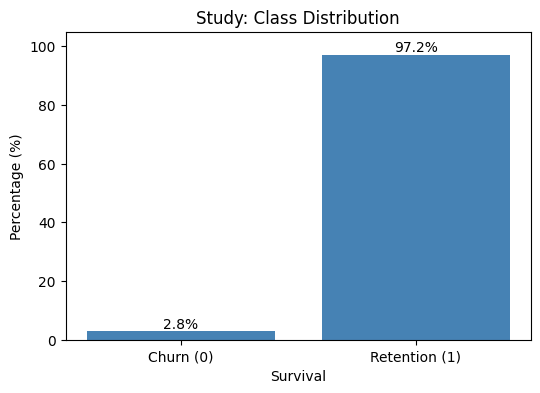

In [12]:
# 1. 비율 계산 (* 100으로 백분율 변환)
ratio = df_study["survived"].value_counts(normalize=True).sort_index() * 100
display(ratio.rename("비율(%)").to_frame())

# 2. 막대그래프 그리기
plt.figure(figsize=(6, 4))
bars = plt.bar(
    ["Churn (0)", "Retention (1)"],   # 0: 이탈, 1: 잔존
    ratio.reindex([0, 1]).values,
    color="steelblue"
)

# 막대 위에 % 수치 표시
plt.bar_label(bars, fmt="%.1f%%")
plt.ylim(0, 105)
plt.xlabel("Survival")
plt.ylabel("Percentage (%)")
plt.title("Study: Class Distribution")
plt.show()

* 잔존 97%, 이탈 3%

In [13]:
# 컬럼별 빈칸 개수 확인
df_study.isnull().sum()

,0
ID,0
survived,0
Month,0
AGE,0
StudyCnt_M1,7
StudyCntCnt_M2,2732
StudyCntCnt_M3,4541
StudyIndex_M1,7
StudyIndex_M2,2732
StudyIndex_M3,4541


### 가설 1. 이탈 직전 월(M1) 학습 횟수가 적은가?

* 이탈하기 직전 달에 공부 횟수(StudyCnt_M1)가 잔류자보다 떨어졌는지 확인

/tmp/ipykernel_995/3091154650.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_study, x='survived', y='StudyCnt_M1', palette='Set2')


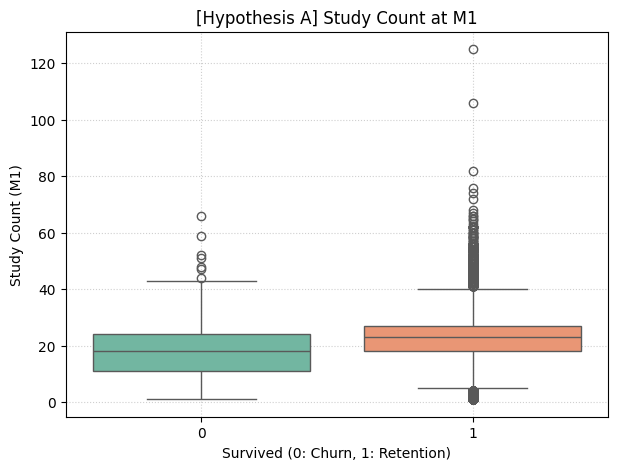

In [14]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_study, x='survived', y='StudyCnt_M1', palette='Set2')

plt.title('[Hypothesis A] Study Count at M1')
plt.xlabel('Survived (0: Churn, 1: Retention)')
plt.ylabel('Study Count (M1)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# 이탈자(0, 초록색)의 중앙값은 약 18회, 잔류자(1, 주황색)의 중앙값은 약 23회
# 이탈 직전 달에 공부를 아예 안 한 것은 아니지만, 잔류자에 비해 활동량이 둔화됨
# 단, 이탈자 중에서도 20회 이상 접속한 사람이 꽤 있어, 이것만으로 이탈을 확정 짓기는 어려움

### 가설 2. 이탈 직전 월(M1) 시험을 안 치르고 건너뛴 비율이 높을까?

* 중단 직전 달의 시험들(Exam1_M1, Exam2_M1, Exam3_M1)에서 결측치(시험 미응시) 비율이 이탈자 쪽에서 치솟는지 확인

<Figure size 800x500 with 0 Axes>

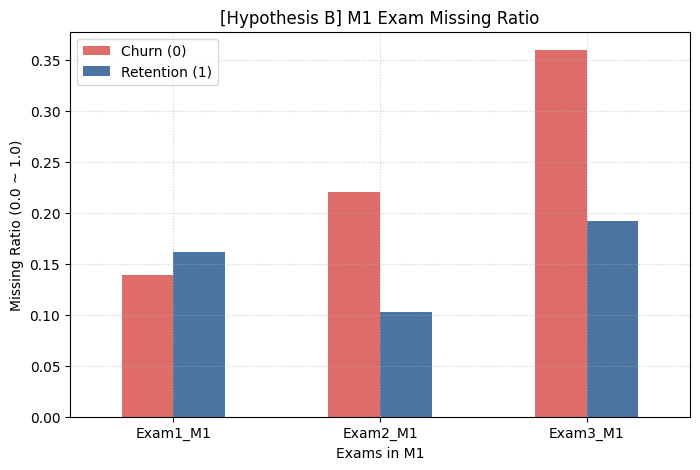

In [15]:
# 0(이탈)과 1(잔류) 그룹별 M1 시험 결측 비율 계산
m1_null_0 = df_study[df_study['survived'] == 0][['Exam1_M1', 'Exam2_M1', 'Exam3_M1']].isnull().mean()
m1_null_1 = df_study[df_study['survived'] == 1][['Exam1_M1', 'Exam2_M1', 'Exam3_M1']].isnull().mean()

m1_exam_null = pd.DataFrame({'Churn (0)': m1_null_0, 'Retention (1)': m1_null_1})

# 막대그래프 출력
plt.figure(figsize=(8, 5))
m1_exam_null.plot(kind='bar', color=['#d9534f', '#2b5c8f'], alpha=0.85, rot=0, figsize=(8, 5))

plt.title('[Hypothesis B] M1 Exam Missing Ratio')
plt.xlabel('Exams in M1')
plt.ylabel('Missing Ratio (0.0 ~ 1.0)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Exam1은 다들 보지만, Exam2와 Exam3로 넘어가는 단계에서 시험을 포기한 사람이 그대로 서비스를 탈퇴
# 예상 원인: 시험에 대한 부담, 성취 달성으로 인한 중단, 보상의 부재

### 가설 3. 학력 지수(StudyIndex_M1)가 낮아서 이탈했을까?

* 기초 학력 수준이나 진도를 따라가는 역량 자체가 부족해서 그만둔 것인지 점검

/tmp/ipykernel_591/1040344467.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_study, x='survived', y='StudyIndex_M1', palette='Pastel1')


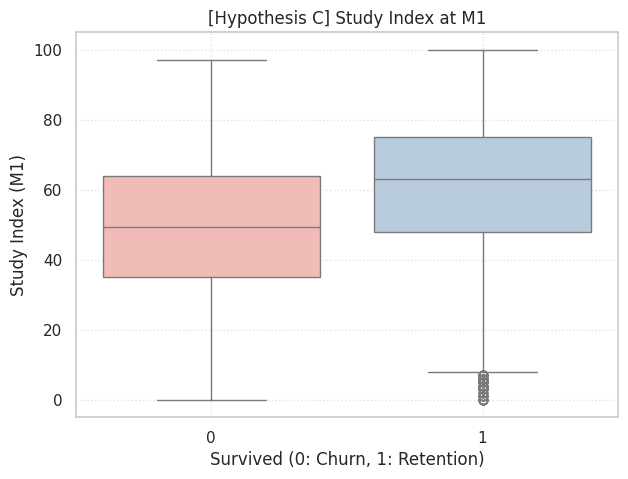

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_study, x='survived', y='StudyIndex_M1', palette='Pastel1')

plt.title('[Hypothesis C] Study Index at M1')
plt.xlabel('Survived (0: Churn, 1: Retention)')
plt.ylabel('Study Index (M1)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# 학력 지수의 차이가 두드러지지 않음
# 학력 지수가 낮다고 해서 무조건 그만두는 것은 아님

## <결론 및 비즈니스 제언>

### 1. 데이터 분석 핵심 요약
* **Exam2, 3 미응시(결측)가 이탈의 결정적 트리거:**
  * 점수 하락이나 학력 지수 부족이 아니라, 중단 직전 월(M1) 심화 시험(Exam2: 22%, Exam3: 36%)을 치르지 않고 건너뛰는 행위가 이탈로 직결됨.

### 2. 이탈 원인에 대한 가설 및 정성 검토 과제
1. **평가 방식 및 난이도 장벽:** 객관식 대비 서술형/실습형 전환, 문항 수 및 소요 시간 급증에 따른 평가 피로도
2. **콘텐츠 흥미 및 동기 부여:** 학습 진도 대비 인터페이스(UI/UX) 불편, 과도한 학습 분량, 피드백 부재
3. **보상(정적 강화) 체계 부재:** 시험 응시 완료에 대한 즉각적 리워드(환급, 뱃지, 핵심 요약집, 다음 강의 언락 등) 부족
4. **목표 달성 후 자연 이탈:** 우수 학습자가 Exam1 단계에서 필요 지식/자격 요건을 충족해 자발적으로 수강을 마쳤을 가능성

### 3. 향후 실행 과제
* **운영 개입:** Exam1 완료 후 Exam2를 미응시한 학습자 감지 시 즉각적인 1:1 상담 및 응시 독려 알림톡 발송
* **모델링 고도화:** M1 시점 시험 결측 여부 및 월별 학습 횟수 감소폭(기울기: $M1 - M2$)을 핵심 파생변수로 반영
* **정성 조사:** 정량 로그 분석으로 확인된 병목 구간(Exam2·Exam3 미응시 집단)을 대상으로 체감 난이도, UI/UX 편의성, 학습 부담 등을 묻는 정성적 만족도 조사를 추가 진행하여 근본적인 이탈 원인 규명